# RIAWELC 데이터 용접 결함 분류

**데이터 출처**: https://github.com/stefyste/RIAWELC

**프로젝트**: 방사선 이미지 용접 결함 자동 분류

**4개클래스**:
1. Crack (균열)
2. Porosity (기공)
3. Excess_Penetration (과도 침투)
4. No_Defect (정상)

In [3]:
%pip install tensorflow-macos
%pip install tensorflow-metal


Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [4]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

/Users/seoki/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
import tensorflow as tf
print("TF version:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))


TF version: 2.16.2
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Num GPUs Available:  1


In [6]:
%pip install matplotlib
%pip install seaborn
%pip install sklearn
%pip install pillow


Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip in

In [7]:
# 라이브러리
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import datetime
import os

plt.style.use('seaborn-v0_8-darkgrid')
print(f'TensorFlow: {tf.__version__}')
print('✅ 라이브러리 로드 완료')

TensorFlow: 2.16.2
✅ 라이브러리 로드 완료


## 1. 설정 - 경로 수정 필수!

In [8]:
# 📁 본인의 데이터 폴더 경로로 수정
DATA_DIR = './Dataset_merged'

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 4

CLASS_NAMES = ['Crack', 'Porosity', 'Excess_Penetration', 'No_Defect']

print('✅ 설정 완료')
print(f'   경로: {DATA_DIR}')
print(f'   클래스: {CLASS_NAMES}')

✅ 설정 완료
   경로: ./Dataset_merged
   클래스: ['Crack', 'Porosity', 'Excess_Penetration', 'No_Defect']


## 2. 데이터 로더

In [9]:
# 폴더이름 잘못입력 했는지 체크함

import os

DATA_DIR = './Dataset_merged'
SUBSETS = ['train', 'validation', 'test']  # train, validation, test 폴더
CLASS_NAMES = ['Crack', 'Porosity', 'Excess_Penetration', 'No_Defect']

for subset in SUBSETS:
    subset_folder = os.path.join(DATA_DIR, subset)
    print(f"\n🔍 Checking subset: {subset}")
    for class_name in CLASS_NAMES:
        class_folder = os.path.join(subset_folder, class_name)
        if os.path.exists(class_folder):
            print(f"✅ Found folder: {class_folder}")
        else:
            print(f"❌ Missing folder: {class_folder}")


🔍 Checking subset: train
✅ Found folder: ./Dataset_merged/train/Crack
✅ Found folder: ./Dataset_merged/train/Porosity
✅ Found folder: ./Dataset_merged/train/Excess_Penetration
✅ Found folder: ./Dataset_merged/train/No_Defect

🔍 Checking subset: validation
✅ Found folder: ./Dataset_merged/validation/Crack
✅ Found folder: ./Dataset_merged/validation/Porosity
✅ Found folder: ./Dataset_merged/validation/Excess_Penetration
✅ Found folder: ./Dataset_merged/validation/No_Defect

🔍 Checking subset: test
✅ Found folder: ./Dataset_merged/test/Crack
✅ Found folder: ./Dataset_merged/test/Porosity
✅ Found folder: ./Dataset_merged/test/Excess_Penetration
✅ Found folder: ./Dataset_merged/test/No_Defect


In [10]:

# #데이터 수 줄이기 코드(너무 많아서... 오래걸림)

# import os
# import random

# DATA_DIR = './Dataset_merged'
# CLASS_NAMES = ['Crack', 'Porosity', 'Excess_Penetration', 'No_Defect']

# def reduce_data_in_folder(folder_path, class_names, max_files=1000):
#     log_file = os.path.join(folder_path, "removed_files.log")
#     with open(log_file, "w") as log:
#         for class_name in class_names:
#             class_folder = os.path.join(folder_path, class_name)
#             if os.path.isdir(class_folder):
#                 files = os.listdir(class_folder)
#                 total_files = len(files)
#                 if total_files <= max_files:
#                     continue
#                 num_files_to_remove = total_files - max_files
#                 files_to_remove = random.sample(files, num_files_to_remove)
#                 for file_name in files_to_remove:
#                     file_path = os.path.join(class_folder, file_name)
#                     os.remove(file_path)
#                     log.write(f"{file_path}\n")
#     print(f"Log of removed files saved to {log_file}")

# # 하위 split 디렉터리 목록
# splits = ['train', 'test', 'validation']

# for split in splits:
#     split_path = os.path.join(DATA_DIR, split)
#     reduce_data_in_folder(split_path, CLASS_NAMES, max_files=1000)


In [11]:
# import os
# import tensorflow as tf

# # 1. 검사할 경로 설정 (test_ds가 사용하는 경로)
# # DATA_DIR 변수가 살아있다고 가정합니다.
# test_path = os.path.join(DATA_DIR, 'test')

# print(f"'{test_path}' 폴더에서 손상되거나 이미지가 아닌 파일을 찾습니다...")
# problem_files = []

# # 2. test_path의 모든 하위 폴더와 파일을 순회합니다.
# for root, dirs, files in os.walk(test_path):
#     for file in files:
#         file_path = os.path.join(root, file)
        
#         # 3. 파일을 읽고 이미지로 디코딩 시도
#         try:
#             # 파일을 바이트로 읽기
#             img_bytes = tf.io.read_file(file_path)
#             # 이미지로 디코딩 시도
#             tf.io.decode_image(img_bytes)
            
#         # 4. 오류 발생 시 (이것이 우리가 찾는 파일!)
#         except tf.errors.InvalidArgumentError as e:
#             if "Unknown image file format" in str(e):
#                 print(f"!! 문제 파일 발견: {file_path}")
#                 problem_files.append(file_path)
#         except Exception as e:
#             # (혹시 모를 다른 오류)
#             print(f"!! 읽기 오류 (이미지 아님?): {file_path}, 오류: {e}")
#             problem_files.append(file_path)

# if not problem_files:
#     print("-> 이미지 파일 형식 문제는 아닌 것 같습니다. (다른 원인)")
# else:
#     print(f"\n총 {len(problem_files)}개의 문제가 있는 파일을 찾았습니다.")
#     print("Finder(탐색기)에서 이 파일들을 직접 찾아서 삭제해 주세요.")

In [12]:
import os

train_dir = './Dataset_merged/train'
for class_name in os.listdir(train_dir):
    class_folder = os.path.join(train_dir, class_name)
    if os.path.isdir(class_folder):
        print(f"Class: {class_name}, Files: {len(os.listdir(class_folder))}")

Class: Porosity, Files: 1000
Class: Crack, Files: 1000
Class: No_Defect, Files: 1000
Class: Excess_Penetration, Files: 1000


In [13]:
def load_dataset(path, augment=False):
        
# 데이터 증강필요없어보임
    # if augment:
    #     datagen = ImageDataGenerator(
    #         rescale=1./255,
    #         rotation_range=15,
    #         width_shift_range=0.15,
    #         height_shift_range=0.15,
    #         horizontal_flip=True,
    #         zoom_range=0.15,
    #         brightness_range=[0.85, 1.15],
    #     )
    # else:
    
    datagen = ImageDataGenerator(rescale=1./255)

    dataset = datagen.flow_from_directory(
        path,
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        color_mode='grayscale',
        shuffle=augment 
    )
    return dataset

print('✅ 데이터 로더 준비')

✅ 데이터 로더 준비


In [14]:
# 데이터 로드
train_path = DATA_DIR + '/train'
val_path = DATA_DIR + '/validation'
test_path = DATA_DIR + '/test'

#  최신 함수를 사용하여 데이터셋 로드
print("Train 데이터셋 로드:")
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    label_mode='categorical',     # loss와 맞춤
    image_size=(IMG_SIZE, IMG_SIZE),
    color_mode='grayscale',      
    batch_size=BATCH_SIZE,
    shuffle=True
)

print("\nValidation 데이터셋 로드:")
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_path,
    label_mode='categorical',
    image_size=(IMG_SIZE, IMG_SIZE),
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    shuffle=False # 검증/테스트 데이터는 섞지 않음
)

print("\nTest 데이터셋 로드:")
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    label_mode='categorical',
    image_size=(IMG_SIZE, IMG_SIZE),
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\n 최신 데이터 로더 준비 완료!")

Train 데이터셋 로드:
Found 4000 files belonging to 4 classes.


2025-11-16 13:10:18.100765: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2025-11-16 13:10:18.100913: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2025-11-16 13:10:18.100923: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2025-11-16 13:10:18.101508: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-11-16 13:10:18.101682: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)



Validation 데이터셋 로드:
Found 4000 files belonging to 4 classes.

Test 데이터셋 로드:
Found 3408 files belonging to 4 classes.

 최신 데이터 로더 준비 완료!


In [15]:
# import os
# import tensorflow as tf

# # 1. (중요) val_path 변수가 이 셀 이전에 정의되어 있어야 합니다!
# #    데이터 로드 셀을 이미 실행했기 때문에 정의되어 있을 것입니다.
# #    (예: val_path = os.path.join(DATA_DIR, 'valid'))

# if 'test_path' not in locals():
#     print("오류: 'val_path' 변수가 정의되지 않았습니다. 데이터 로드 셀을 먼저 실행하세요.")
# else:
#     print(f"'{test_path}' 폴더에서 손상되거나 이미지가 아닌 파일을 찾습니다...")
#     problem_files = []

#     # 2. val_path의 모든 하위 폴더와 파일을 순회합니다.
#     for root, dirs, files in os.walk(val_path):
#         for file in files:
#             file_path = os.path.join(root, file)
            
#             # 3. 파일을 읽고 이미지로 디코딩 시도
#             try:
#                 img_bytes = tf.io.read_file(file_path)
#                 # ⭐️ 디코딩 시도
#                 tf.io.decode_image(img_bytes)
                
#             # 4. 오류 발생 시 (이것이 우리가 찾는 파일!)
#             except tf.errors.InvalidArgumentError as e:
#                 if "Unknown image file format" in str(e):
#                     print(f"!! 문제 파일 발견: {file_path}")
#                     problem_files.append(file_path)
#             except Exception as e:
#                 # (혹시 모를 다른 오류)
#                 print(f"!! 읽기 오류 (이미지 아님?): {file_path}, 오류: {e}")
#                 problem_files.append(file_path)

#     if not problem_files:
#         print(f"-> '{val_path}'에서 이미지 파일 형식 문제는 찾지 못했습니다.")
#     else:
#         print(f"\n총 {len(problem_files)}개의 문제가 있는 파일을 찾았습니다.")
#         print("Finder(탐색기)에서 이 파일들을 직접 찾아서 삭제해 주세요.")

## 3. 모델 구축

In [16]:
def create_model():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    
    x = layers.Rescaling(1./255)(inputs)
    x = layers.RandomFlip('horizontal')(inputs)
    x = layers.RandomRotation(0.1)(x)
    x = layers.RandomZoom(0.1)(x)

    # Conv Block 1
    x = layers.Conv2D(64, 3, padding='same', kernel_regularizer=regularizers.l2(0.001))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)

    # Conv Block 2
    x = layers.Conv2D(128, 3, padding='same', kernel_regularizer=regularizers.l2(0.001))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.3)(x)

    # Conv Block 3
    x = layers.Conv2D(256, 3, padding='same', kernel_regularizer=regularizers.l2(0.001))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.4)(x)

    # Dense
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, kernel_regularizer=regularizers.l2(0.001))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    return keras.Model(inputs=inputs, outputs=outputs)

# 모델 생성
model = create_model()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 1)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 64)   │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 439,300 (1.68 MB)

 Trainable params: 437,892 (1.67 MB)

 Non-trainable params: 1,408 (5.50 KB)

## 4. 모델 학습

In [17]:
import os
import datetime
from tensorflow import keras


# 모델 컴파일(손실함수 변경)
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# 얼리스탑 설정
#  5-> 10 변경
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=10, 
    restore_best_weights=True
)

# 텐서보드 로그
log_dir = os.path.join(os.getcwd(), 'logs', datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
tensorboard_callback = keras.callbacks.TensorBoard(
    log_dir=log_dir, 
    histogram_freq=1
)

# 최고 성능 모델 저장
#'val_accuracy' 대신 'val_loss'로 변경 
checkpoint = keras.callbacks.ModelCheckpoint(
    'best_model.keras',     
    monitor='val_loss',     # 'val_loss'로 기준 변경함
    save_best_only=True,  # 가장 좋은 모델만 저장
    mode='min'              # val_loss이니 'min' 모드 사용
)

# 학습률 자동 조절
# 'val_loss'가 5번(patience) 개선되지 않으면 학습률을 0.5배(factor)로 줄임
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-7 # 최소 학습률
)

print(f'✅ 콜백 준비 완료')


# 학습 시작
history = model.fit(train_ds, epochs=50, validation_data=val_ds,
                   callbacks=[early_stop, tensorboard_callback, checkpoint, reduce_lr], 
                   verbose=1)

print('✅ 학습 완료!')


✅ 콜백 준비 완료
Epoch 1/50


2025-11-16 13:10:19.408013: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


125/125 ━━━━━━━━━━━━━━━━━━━━ 88s 673ms/step - accuracy: 0.3758 - loss: 2.0137 - val_accuracy: 0.2567 - val_loss: 2.0321 - learning_rate: 0.0010
Epoch 2/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 82s 657ms/step - accuracy: 0.4284 - loss: 1.7985 - val_accuracy: 0.4270 - val_loss: 1.7207 - learning_rate: 0.0010
Epoch 3/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 83s 667ms/step - accuracy: 0.4608 - loss: 1.6785 - val_accuracy: 0.2680 - val_loss: 2.2851 - learning_rate: 0.0010
Epoch 4/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 84s 673ms/step - accuracy: 0.4621 - loss: 1.5698 - val_accuracy: 0.2582 - val_loss: 2.5703 - learning_rate: 0.0010
Epoch 5/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 84s 672ms/step - accuracy: 0.4908 - loss: 1.4744 - val_accuracy: 0.2842 - val_loss: 1.7698 - learning_rate: 0.0010
Epoch 6/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 84s 669ms/step - accuracy: 0.4749 - loss: 1.4300 - val_accuracy: 0.2637 - val_loss: 1.9073 - learning_rate: 0.0010
Epoch 7/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 85s 679ms/step - accuracy: 0.5031 - loss:

In [18]:
print(f'TensorBoard 실행 (별도 셀):')

%load_ext tensorboard
%tensorboard --logdir logs

TensorBoard 실행 (별도 셀):


## 5. 평가

In [19]:
test_loss, test_acc = model.evaluate(test_ds, verbose=2)

print('\n테스트 정확도:', test_acc)
print('\n테스트 손실:', test_loss)


107/107 - 10s - 91ms/step - accuracy: 0.7767 - loss: 0.6369

테스트 정확도: 0.7767018675804138

테스트 손실: 0.6368733644485474


## 6. 시각화

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step


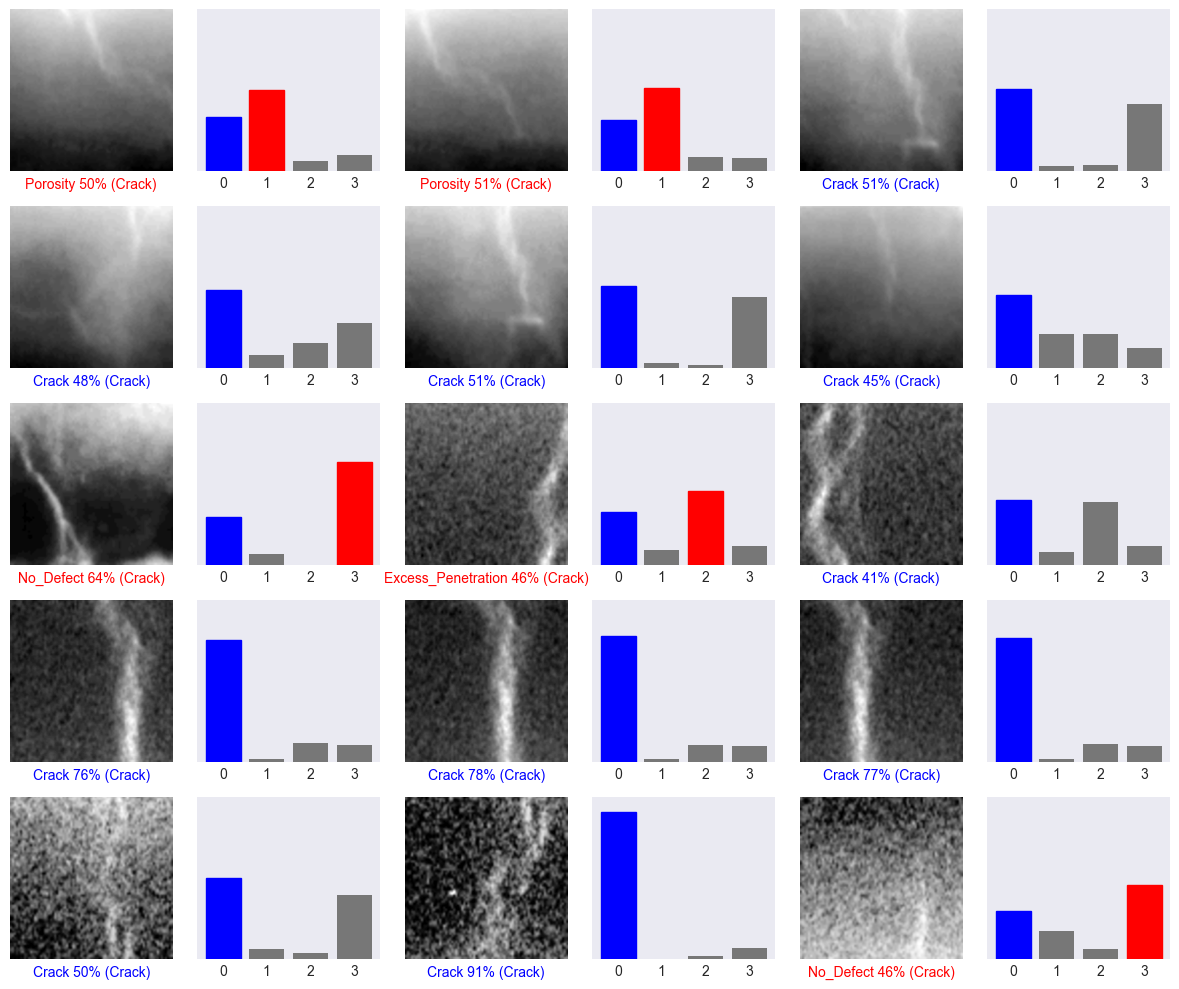

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# 1. ⭐️ iter()를 사용하여 test_ds에서 배치를 가져옵니다.
images, labels = next(iter(test_ds))

# 2. 모델 예측 수행
predictions = model.predict(images)

# 3. ⭐️ (중요) 텐서(Tensor)를 Numpy 배열로 변환합니다.
# Matplotlib/Numpy 함수는 텐서를 직접 처리하지 못합니다.
images_np = images.numpy()
labels_np = labels.numpy()

# 4. 클래스 이름 (이 변수가 이전에 정의되어 있어야 함)
# 예: class_names = ['Crack', 'Porosity', 'Excess_Penetration', 'No_Defect']
class_names = CLASS_NAMES 

# --- 시각화 함수 2개 (수정 불필요) ---
def plot_image(predictions_array, true_label_array, img):
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])

  # (H, W, 1) -> (H, W)로 변경하여 흑백 이미지 표시
  plt.imshow(np.squeeze(img), cmap=plt.cm.binary) 

  predicted_label = np.argmax(predictions_array)
  # true_label_array는 [0, 0, 1, 0] (one-hot) 형식이므로 argmax로 변환
  true_label = np.argmax(true_label_array) 
  
  color = 'blue' if predicted_label == true_label else 'red'

  plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                100*np.max(predictions_array),
                                class_names[true_label]),
                                color=color)

def plot_value_array(predictions_array, true_label_array):
  plt.grid(False)
  num_classes = len(class_names) # 4
  plt.xticks(range(num_classes))
  plt.yticks([])

  thisplot = plt.bar(range(num_classes), predictions_array, color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(predictions_array)
  true_label = np.argmax(true_label_array)

  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')

# --- 시각화 실행 (Numpy 변수 사용) ---
num_rows = 5
num_cols = 3
num_images = num_rows * num_cols

plt.figure(figsize=(2 * 2 * num_cols, 2 * num_rows))
for i in range(num_images):
  # ⭐️ 배치 크기(예: 32)보다 i가 커지면 중단
  if i >= len(images_np): 
      break
      
  plt.subplot(num_rows, 2 * num_cols, 2 * i + 1)
  # ⭐️ Numpy 배열(images_np, labels_np)을 전달합니다.
  plot_image(predictions[i], labels_np[i], images_np[i])
  
  plt.subplot(num_rows, 2 * num_cols, 2 * i + 2)
  # ⭐️ Numpy 배열(labels_np)을 전달합니다.
  plot_value_array(predictions[i], labels_np[i])

plt.tight_layout()
plt.show()

# 시각화 2

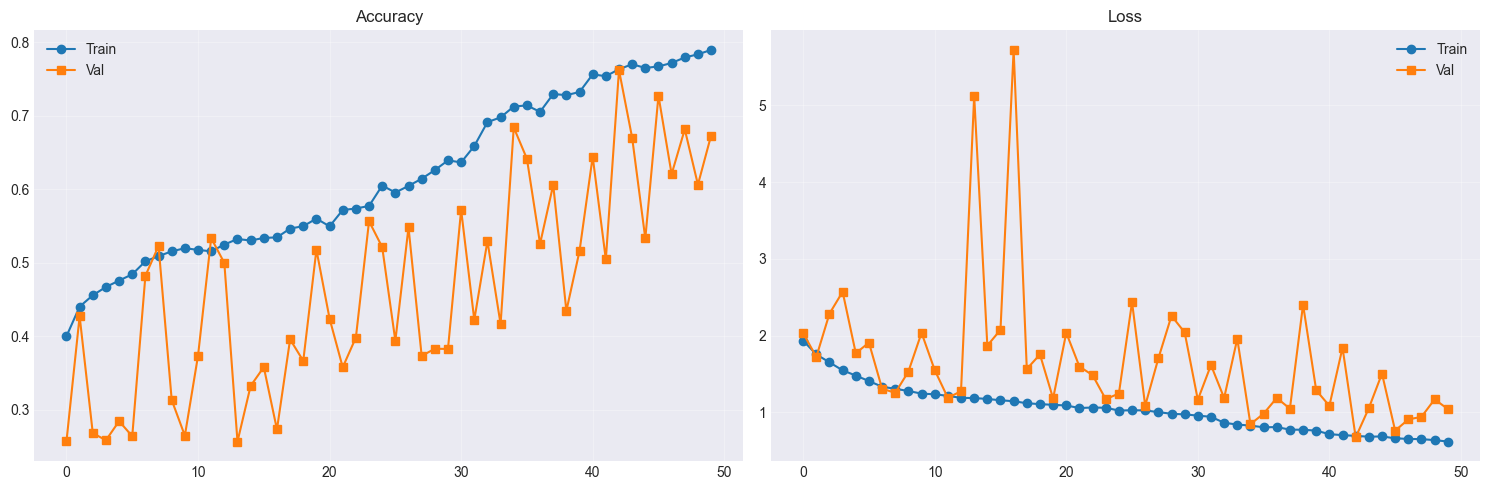

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(history.history['accuracy'], 'o-', label='Train')
axes[0].plot(history.history['val_accuracy'], 's-', label='Val')
axes[0].set_title('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history['loss'], 'o-', label='Train')
axes[1].plot(history.history['val_loss'], 's-', label='Val')
axes[1].set_title('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('curves.png', dpi=150)
plt.show()

107/107 ━━━━━━━━━━━━━━━━━━━━ 9s 87ms/step


2025-11-16 14:20:46.773622: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


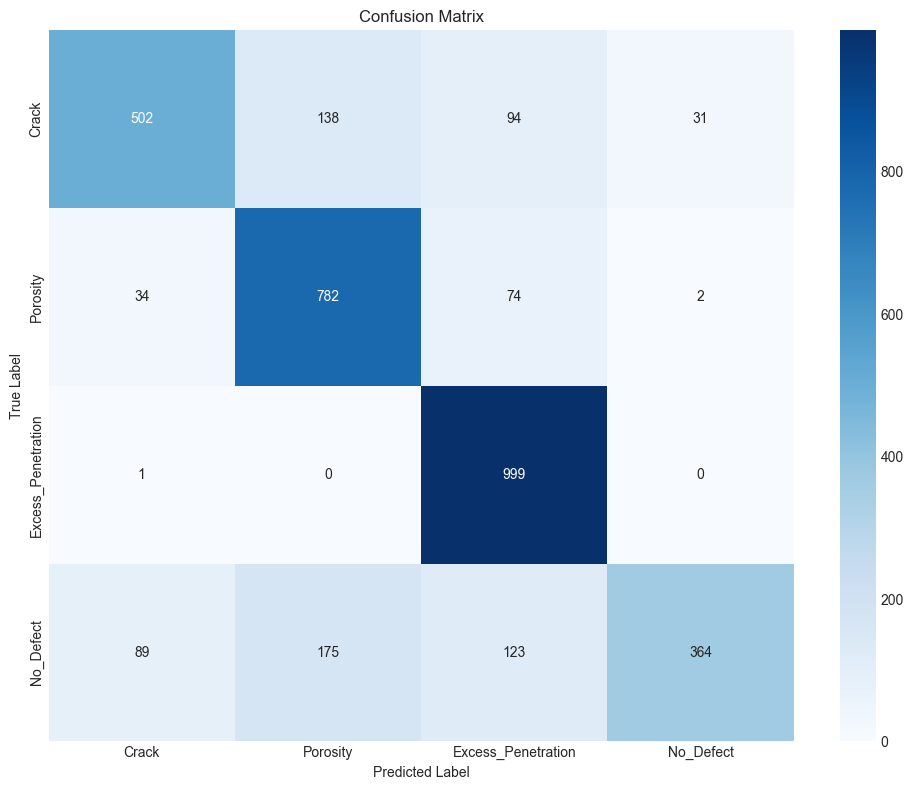


 분류 리포트 (Classification Report):

                    precision    recall  f1-score   support

             Crack       0.80      0.66      0.72       765
          Porosity       0.71      0.88      0.79       892
Excess_Penetration       0.77      1.00      0.87      1000
         No_Defect       0.92      0.48      0.63       751

          accuracy                           0.78      3408
         macro avg       0.80      0.75      0.75      3408
      weighted avg       0.80      0.78      0.76      3408



In [22]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

predictions = model.predict(test_ds, verbose=1)
pred_labels = np.argmax(predictions, axis=1)

true_labels_list = []
for images, labels in test_ds:
    true_labels_list.append(labels.numpy()) # 텐서를 numpy로 변환하여 리스트에 추가

true_labels_raw = np.concatenate(true_labels_list, axis=0)

#  라벨 형식 통일
true_labels = np.argmax(true_labels_raw, axis=1)


# 혼동 행렬 계산 및 시각화
cm = confusion_matrix(true_labels, pred_labels)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

# 분류 리포트 출력
print("\n 분류 리포트 (Classification Report):\n")
print(classification_report(true_labels, pred_labels, target_names=CLASS_NAMES))